we'll build a model to segment those households into distinct clusters, and examine the differences between those clusters.you’ll apply k-means clustering to group credit-challenged households based on home value and debt levels. You’ll determine the optimal number of clusters using inertia and silhouette scores, and visualize results with scatter plots and bar charts.

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving SCFP2019.csv to SCFP2019 (1).csv


In [ ]:
import pandas as pd
def wrangle(filepath):
  df=pd.read_csv(filepath)
  mask=df["TURNFEAR"]==1
  df=df[mask]
  return df

Create a wrangle function that takes a path of a CSV file as input, reads the file into a DataFrame, subsets the data to households that have been turned down for credit or feared being denied credit in the past 5 years (see "TURNFEAR"), and returns the subset DataFrame.

In [ ]:
df=wrangle("SCFP2019.csv")
print("df shape:",df.shape)
print("df type:",type(df))
print(df.head())

df shape: (4623, 362)
df type: <class 'pandas.core.frame.DataFrame'>
   YY1  Y1          WGT  HHSEX  AGE  AGECL  EDUC  EDCL  MARRIED  KIDS  ...  \
5    2  21  3790.476607      1   50      3     8     2        1     3  ...   
6    2  22  3798.868505      1   50      3     8     2        1     3  ...   
7    2  23  3799.468393      1   50      3     8     2        1     3  ...   
8    2  24  3788.076005      1   50      3     8     2        1     3  ...   
9    2  25  3793.066589      1   50      3     8     2        1     3  ...   

   NWCAT  INCCAT  ASSETCAT  NINCCAT  NINC2CAT  NWPCTLECAT  INCPCTLECAT  \
5      1       2         1        2         1           1            4   
6      1       2         1        2         1           1            4   
7      1       2         1        2         1           1            4   
8      1       2         1        2         1           1            4   
9      1       2         1        2         1           1            4   

   NINCPCTLECAT  

Create a scatter plot of that shows the total value of primary residence of a household ("HOUSES") as a function of the total value of household debt ("DEBT"). Be sure to label your x-axis as "Household Debt", your y-axis as "Home Value", and use the title "Credit Fearful: Home Value vs. Household Debt".

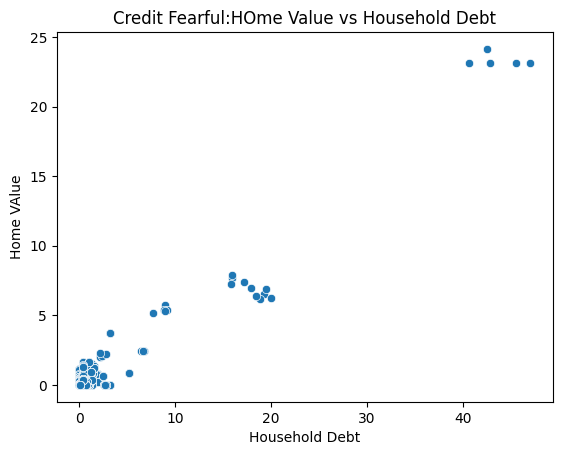

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.scatterplot(
    x=df["HOUSES"]/1e6,
    y=df["DEBT"]/1e6

)
plt.xlabel("Household Debt")
plt.ylabel("Home VAlue")
plt.title("Credit Fearful:HOme Value vs Household Debt")
plt.show();

                SPLIT

   We need to split our data, but we're not going to need target vector or a test set this time around. That's because the model we'll be building involves unsupervised learning. It's called unsupervised because the model doesn't try to map input to a st of labels or targets that already exist. It's kind of like how humans learn new skills, in that we don't always have models to copy. Sometimes, we just try out something and see what happens. Keep in mind that this doesn't make these models any less useful, it just makes them different.

In [ ]:
# Create the feature matrix X. It should contain two features only: "DEBT" and "HOUSES".
X=df[["DEBT","HOUSES"]]
print("x shape:",X.shape)
print("x type:",type(X))
print(X.head())

x shape: (4623, 2)
x type: <class 'pandas.core.frame.DataFrame'>
           DEBT  HOUSES
5  15477.033113     0.0
6  15984.476821     0.0
7  19409.721854     0.0
8  17887.390728     0.0
9  19536.582781     0.0


       BUILD Model

Clustering is a branch of unsupervised machine learning where the goal is to identify groups or clusters in your data set without the use of labels. Clustering should not be considered the same as classification. We are not trying make predictions on observations from a set of pre-defined classes. In clustering, you are identifying a set of similar data points and calling the resulting set a cluster.

In [ ]:
#Run the cell below to display the ClusterWidget
import teaching_tools
from teaching_tools.widgets import ClusterWidget
cw = ClusterWidget(n_clusters=3)
cw.show()


Take a second and run slowly through all the positions on the slider. At the first position, there's whole bunch of gray datapoints, and if you look carefully, you'll see there are also three stars. Those stars are the centroids. At first, their position is set randomly. If you move the slider one more position to the right, you'll see all the gray points change colors that correspond to three clusters.

Since a centroid represents the mean value of all the data in the cluster, we would expect it to fall in the center of whatever cluster it's in. That's what will happen if you move the slider one more position to the right. See how the centroids moved?

Aha! But since they moved, the datapoints might not be in the right clusters anymore. Move the slider again, and you'll see the data points redistribute themselves to better reflect the new position of the centroids. The new clusters mean that the centroids also need to move, which will lead to the clusters changing again, and so on, until all the datapoints end up in the right cluster with a centroid that reflects the mean value of all those points.

In [ ]:
#Let's see what happens when we try the same with our "DEBT" and "HOUSES" data.
#Run the cell below to display the SCFClusterWidget.
from teaching_tools.widgets import SCFClusterWidget
ss=SCFClusterWidget(df["HOUSES"],df["DEBT"],n_clusters=3)
ss.show()



Iterate

In [ ]:
#Build a KMeans model, assign it to the variable name model, and fit it to the training data X
from sklearn.cluster import KMeans

model = KMeans(n_clusters=3, random_state=42)
print("model type:",type(model))
model.fit(X)

model type: <class 'sklearn.cluster._kmeans.KMeans'>


KMeans(n_clusters=3, random_state=42)

In [ ]:
# Extract the labels that your model created during training and assign them to the variable labels
labels=model.labels_
print("labels type:",type(labels))
print("labels shape:",labels.shape)
labels[:10]

labels type: <class 'numpy.ndarray'>
labels shape: (4623,)


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=int32)

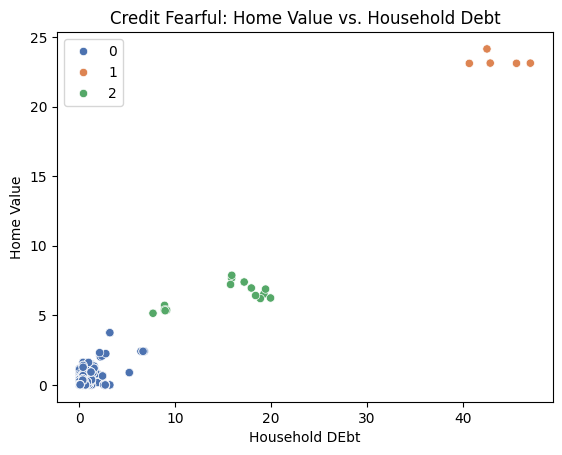

In [ ]:
#Recreate the "Home Value vs. Household Debt" scatter plot you made above, but with two changes. First, use seaborn to create the plot.
#Second, pass your labels to the hue argument, and set the palette argument to "deep"
sns.scatterplot(
    x=df["HOUSES"]/1e6,
    y=df["DEBT"]/1e6,
    hue=labels,
    palette="deep"
)
plt.xlabel("Household DEbt")
plt.ylabel("Home Value")
plt.title("Credit Fearful: Home Value vs. Household Debt");

In [ ]:
#Extract the centroids that your model created during training, and assign them to the variable centroids.
centriods=model.cluster_centers_
print("centriods type:",type(centriods))
print("centriods shape:",centriods.shape)
print(centriods)

centriods type: <class 'numpy.ndarray'>
centriods shape: (3, 2)
[[  115465.74289955   147349.33895374]
 [23322239.7086     43746722.11920001]
 [ 6426520.84769333 14800441.50095333]]


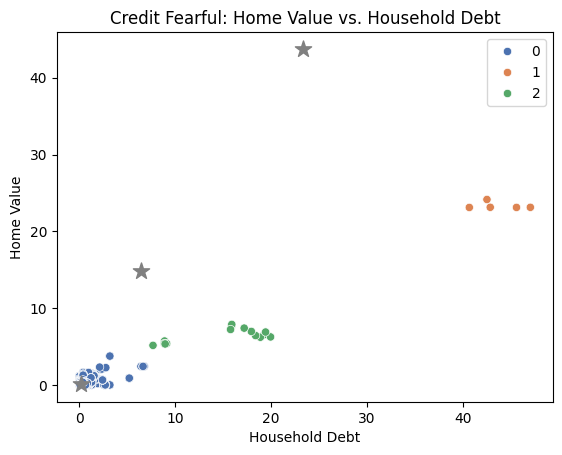

In [ ]:
#Recreate the seaborn "Home Value vs. Household Debt" scatter plot you just made, but with one difference: Add the centroids to the plot. Be sure to set the centroids color to "gray".
sns.scatterplot(
    x=df["HOUSES"]/1e6,
    y=df["DEBT"]/1e6,
    hue=labels,
    palette="deep"
)
plt.scatter(
    x=centriods[:,0]/1e6,
    y=centriods[:,1]/1e6,
    color="gray",
    marker="*",
    s=150
)
plt.xlabel("Household Debt")
plt.ylabel("Home Value")
plt.title("Credit Fearful: Home Value vs. Household Debt")
plt.show()

That looks great, but let's not pat ourselves on the back just yet. Even though our graph makes it look like the clusters are correctly assigned but, as data scientists, we need a numerical evaluation. The data we're using is pretty clear-cut, but if things were a little more muddled, we'd want to run some calculations to make sure we got everything right.

There are two metrics that we'll use to evaluate our clusters. We'll start with inertia, which measure the distance between the points within the same cluster.

Inertia in K-Means is the sum of squared distances between each data point and the centroid of the cluster it belongs to.

In simple English, inertia measures how tightly grouped your data points are around their cluster centres.
- Low inertia: Data points are close to their centroids.
- High inertia: Data points are far from their centroids.

Extract the inertia for your model and assign it to the variable inertia.

In [ ]:
inertia=model.inertia_
print("inertia type:",type(inertia))
print("inertia value:",inertia)

inertia type: <class 'float'>
inertia value: 1512089553334307.8


The "best" inertia is 0, and our score is pretty far from that. Does that mean our model is "bad?" Not necessarily. Inertia is a measurement of distance (like mean absolute error ). This means that the unit of measurement for inertia depends on the unit of measurement of our x- and y-axes. And since "DEBT" and "HOUSES" are measured in tens of millions of dollars, it's not surprising that inertia is so large.

However, it would be helpful to have metric that was easier to interpret, and that's where silhouette score comes in. Silhouette score measures the distance between different clusters. It ranges from -1 (the worst) to 1 (the best), so it's easier to interpret than inertia.

Silhouette Coefficient is a measure of how dense and separated the clusters are. The silhouette coefficient is a property assigned to each data point. It's equal to:

**S = (b - a) / max(a, b)**

where **a** is the distance between a point and the centroid of its assigned cluster; **b** is the distance between the point and the centroid of the nearest neighboring cluster (i.e. the closest cluster the point is not assigned to).

The silhouette coefficient ranges from -1 to 1. If a point is really close to the centroid of its assigned cluster, then **a is small** and the silhouette coefficient will be approximately equal to 1. If the reverse is true, **a is large compared to b**, then the coefficient will be -1. If the point could have been assigned to either cluster, its coefficient will be 0.

Higher silhouette coefficient means higher density and highly separated clusters. This is because we want to have lower **a** (close to assigned cluster's centroid) and higher **b** (far away from unassigned cluster's centroid). A lower **a** value combined with higher **b** value will produce a higher silhouette score.

In [ ]:
#Calculate the silhouette score for your model and assign it to the variable ss.
from sklearn.metrics import silhouette_score
ss=silhouette_score(X,labels)
print("silhouette score type:",type(ss))
print("silhouette score value:",ss)

silhouette score type: <class 'numpy.float64'>
silhouette score value: 0.9768842462942853


Outstanding! 0.976 is pretty close to 1, so our model has done a good job at identifying 3 clusters that are far away from each other.

It's important to remember that these performance metrics are the result of the number of clusters we told our model to create. In unsupervised learning, the number of clusters is hyperparameter that you set before training your model. So what would happen if we change the number of clusters? Will it lead to better performance? Let's try!

In [ ]:

#Use a for loop to build and train a K-Means model where n_clusters ranges from 2 to 12 (inclusive). Each time a model is trained,
# calculate the inertia and add it to the list inertia_errors, then calculate the silhouette score and add it to the list silhouette_scores.

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Use a for loop to build and train K-Means models
n_clusters = range(2, 12)

inertia_errors = []
silhouette_scores = []

for k in n_clusters:

    # Build our model
    model = KMeans(n_clusters=k, random_state=42)

    # Train the model
    model.fit(X)

    # Calculate inertia
    inertia_errors.append(model.inertia_)

    # Calculate the silhouette score
    silhouette_scores.append(
        silhouette_score(X, model.labels_)
    )

print("inertia_errors type:", type(inertia_errors))
print("inertia_errors len:", len(inertia_errors))
print("Inertia:", inertia_errors)
print()

print("silhouette_scores type:", type(silhouette_scores))
print("silhouette_scores len:", len(silhouette_scores))
print("Silhouette Scores:", silhouette_scores)


inertia_errors type: <class 'list'>
inertia_errors len: 10
Inertia: [4857138762434612.0, 1512089553334307.8, 878874810989194.8, 503658338106157.44, 417382852066033.4, 306225138216238.44, 294230556095534.75, 221858391632304.22, 162998596818817.03, 152015096047834.66]

silhouette_scores type: <class 'list'>
silhouette_scores len: 10
Silhouette Scores: [0.9855099957518804, 0.9768842462942853, 0.9490311483405012, 0.814573520611849, 0.8098677144699669, 0.7283895532731133, 0.7292682050656363, 0.7303424143003588, 0.7332193680823375, 0.7338888149463328]


Now that we have both performance metrics for several different settings of n_clusters, let's make some line plots to see the relationship between the number of clusters in a model and its inertia and silhouette scores.

Create a line plot that shows the values of inertia_errors as a function of n_clusters. Be sure to label your x-axis "Number of Clusters", your y-axis "Inertia", and use the title "K-Means Model: Inertia vs Number of Clusters".

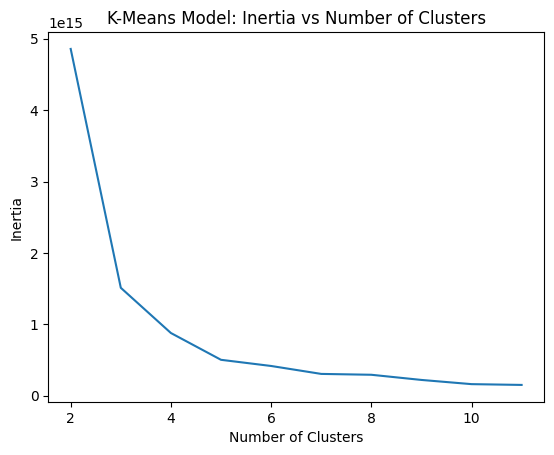

In [ ]:
plt.plot(n_clusters,inertia_errors)
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("K-Means Model: Inertia vs Number of Clusters")
plt.show();

What we're seeing here is that, as the number of clusters increases, inertia goes down. In fact, we could get inertia to 0 if we told our model to make 4,623 clusters (the same number of observations in X), but those clusters wouldn't be helpful to us.

The trick with choosing the right number of clusters is to look for the "bend in the elbow" for this plot. In other words, we want to pick the point where the drop in inertia becomes less dramatic and the line begins to flatten out. In this case, it looks like the sweet spot is 4 or 5.

Create a line plot that shows the values of silhouette_scores as a function of n_clusters. Be sure to label your x-axis "Number of Clusters", your y-axis "Silhouette Score", and use the title "K-Means Model: Silhouette Score vs Number of Clusters"

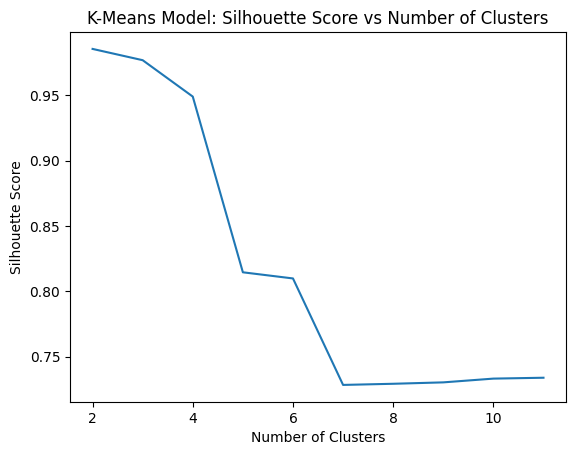

In [ ]:
# Plot silhouette_scores vs n_clusters
plt.plot(n_clusters, silhouette_scores)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("K-Means Model: Silhouette Score vs Number of Clusters")

plt.show()


Note that, in contrast to our inertia plot, bigger is better. So we're not looking for a "bend in the elbow" but rather a number of clusters for which the silhouette score still remains high. We can see that silhouette score drops drastically beyond 4 clusters. Given this and what we saw in the inertia plot, it looks like the optimal number of clusters is 4.

Build and train a new k-means model named final_model. Use the information you gained from the two plots above to set an appropriate value for the n_clusters argument. Once you've built and trained your model, submit it to the grader for evaluation.

In [ ]:
final_model=KMeans(n_clusters=4,random_state=42)
final_model.fit(X)

KMeans(n_clusters=4, random_state=42)

communication

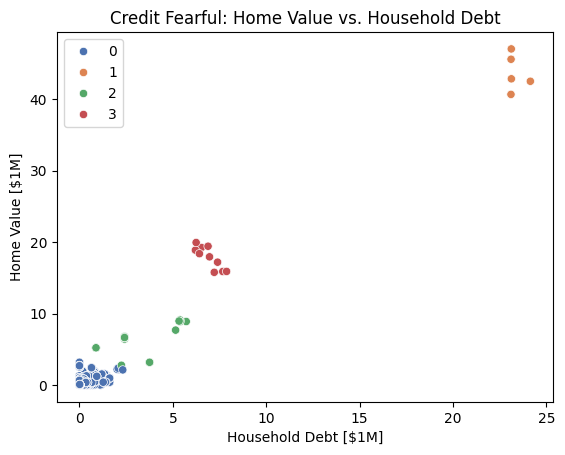

In [ ]:
# Create one last "Home Value vs. Household Debt" scatter plot that shows the clusters that your final_model has assigned to the training data
sns.scatterplot(
    x=df["DEBT"] / 1e6,
    y=df["HOUSES"] / 1e6,
    hue=final_model.labels_,
    palette="deep"
)
plt.xlabel("Household Debt [$1M]")
plt.ylabel("Home Value [$1M]")
plt.title("Credit Fearful: Home Value vs. Household Debt");

 You can see all four of our clusters, each differentiated from the rest by color.

In [ ]:
#Create a DataFrame xgb that contains the mean "DEBT" and "HOUSES" values for each of the clusters in your final_model.
xgb=X.groupby(final_model.labels_).mean()
print("xgb type:",type(xgb))
print("xgb shape:",xgb.shape)
print(xgb)

xgb type: <class 'pandas.core.frame.DataFrame'>
xgb shape: (4, 2)
           DEBT        HOUSES
0  1.076875e+05  1.309043e+05
1  2.332224e+07  4.374672e+07
2  3.071212e+06  5.773984e+06
3  6.942845e+06  1.785441e+07


Create a side-by-side bar chart from xgb that shows the mean "DEBT" and "HOUSES" values for each of the clusters in your final_model. For readability, you'll want to divide the values in xgb by 1 million. Be sure to label the x-axis "Cluster", the y-axis "Value [$1 million]", and use the title "Mean Home Value & Household Debt by Cluster"

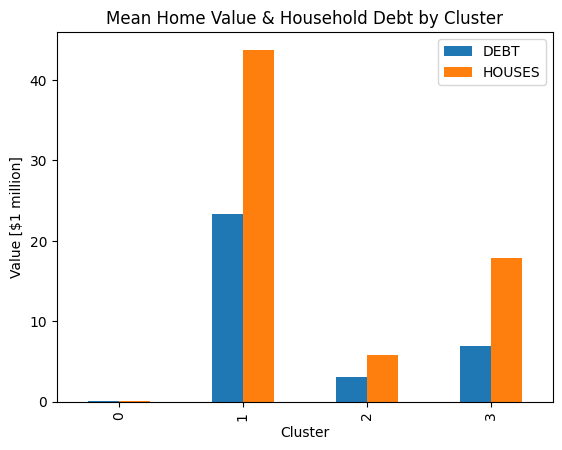

In [ ]:
(xgb/1e6).plot(kind="bar")
plt.xlabel("Cluster")
plt.ylabel("Value [$1 million]")
plt.title("Mean Home Value & Household Debt by Cluster");

Text(0.5, 1.0, 'Household Debt to Home Value Ratio by Cluster')

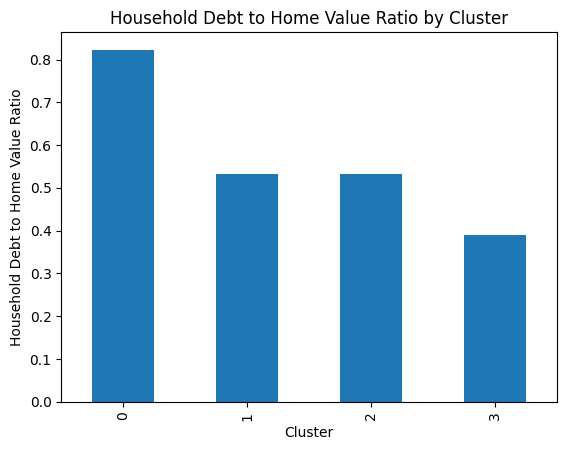

In [ ]:
(xgb["DEBT"]/xgb["HOUSES"]).plot(kind="bar")
plt.xlabel("Cluster")
plt.ylabel("Household Debt to Home Value Ratio")
plt.title("Household Debt to Home Value Ratio by Cluster")

In this plot, we have our four clusters spread across the x-axis, and the dollar amounts for home value and household debt on the y-axis.

The first thing to look at in this chart is the different mean home values for the five clusters. Clusters 0 represents households with small to moderate home values, clusters 2 and 3 have high home values, and cluster 1 has extremely high values.

The second thing to look at is the proportion of debt to home value. In clusters 1 and 3, this proportion is around 0.5. This suggests that these groups have a moderate amount of untapped equity in their homes. But for group 0, it's almost 1, which suggests that the largest source of household debt is their mortgage. Group 2 is unique in that they have the smallest proportion of debt to home value, around 0.4.